# Build your own world model

Every model in `torch_world` subclasses one of two base classes:

| base class | you write | you get |
|---|---|---|
| `models.JEPA` | `forward(...) -> {"loss": ...}` | `make_target_encoder`, `update_target` (EMA) |
| `models.WorldModel` | `encode`, `predict(z, actions)`, `forward` | `rollout`, `cost`, planning with `planning.CEM` |

The parts come from the shared modules: `nn` (ViT, transformer blocks, RoPE, masked predictor), `masks` (multi-block, causal), `losses` (SIGReg, InfoNCE), `envs`, `datasets` and `plots`. Below we write a new world model in about 30 lines, then train it and plan with it without any further code.

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader

from torch_world import plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import PointMass, run_policy
from torch_world.losses import SIGReg
from torch_world.models import WorldModel
from torch_world.nn import MLP
from torch_world.planning import CEM

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## The model
A convolutional encoder, residual MLP dynamics, and SIGReg against collapse: a minimal LeWM-style JEPA. The only contract is that `predict(z, actions)` maps step `t` to step `t + 1`.

In [2]:
class ConvJEPA(WorldModel):
    history = 1

    def __init__(self, action_dim: int, dim: int = 32, lamb: float = 0.01):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1), nn.GELU(),
            nn.Conv2d(32, 64, 4, 2, 1), nn.GELU(),
            nn.Conv2d(64, 64, 4, 2, 1), nn.GELU(),
            nn.Flatten(), nn.Linear(64 * 4 * 4, dim),
        )
        self.dynamics = MLP([dim + action_dim, 256, 256, dim])
        self.sigreg = SIGReg(256)
        self.lamb = lamb

    def encode(self, pixels):
        return self.encoder(pixels.flatten(0, 1)).unflatten(0, pixels.shape[:2])

    def predict(self, z, actions):
        return z + self.dynamics(torch.cat([z, actions], dim=-1))

    def forward(self, pixels, actions):
        z = self.encode(pixels)
        pred = (self.predict(z[:, :-1], actions[:, :-1]) - z[:, 1:]).square().mean()
        sigreg = self.sigreg(z.transpose(0, 1))
        return {"loss": pred + self.lamb * sigreg, "prediction": pred, "SIGReg": sigreg}


model = ConvJEPA(action_dim=2).to(device)

## Train

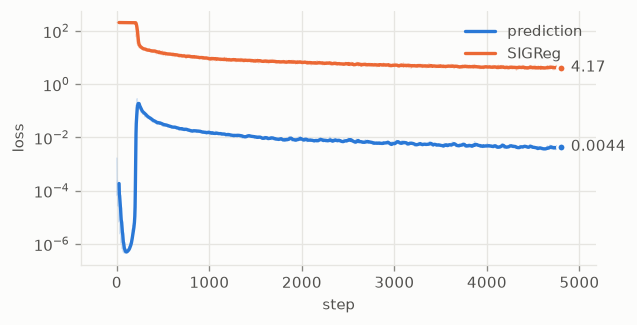

In [3]:
data = {k: v.to(device) for k, v in PointMass(batch_size=4096, size=32).collect(16).items()}
loader = DataLoader(TrajectoryDataset(data, 2), batch_size=512, shuffle=True, drop_last=True)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3)

log = {"prediction": [], "SIGReg": []}
for epoch in range(40):
    for batch in loader:
        out = model(batch["pixels"], batch["actions"])
        opt.zero_grad()
        out["loss"].backward()
        opt.step()
        for k in log:
            log[k].append(out[k].item())
model.eval()
plots.curves(log)

## Plan with it
`rollout`, `cost` and `CEM` come with `WorldModel`.

success rate (within 0.1)   ConvJEPA + CEM 0.62   random 0.00


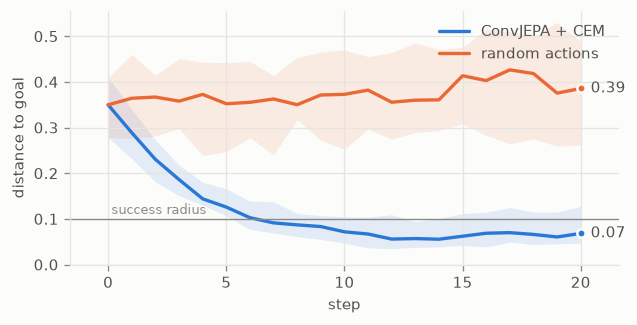

In [4]:
env = PointMass(batch_size=32, size=32, device=device)
env.reset(generator=torch.Generator().manual_seed(1))
start, goals = env.state.clone(), env.sample_goals((0.2, 0.5), generator=torch.Generator().manual_seed(2))
planner = CEM(horizon=5, action_dim=2, num_samples=512, num_elites=48, iterations=10, bounds=(-1, 1))
with torch.no_grad():
    goal = model.encode(env.render(goals)[:, None])[:, 0]

paths = run_policy(env, lambda obs: planner(model, model.encode(obs[:, None]), goal)[:, 0], steps=20)
env.reset(start)
random = run_policy(env, lambda obs: torch.rand(len(obs), 2, device=device) * 2 - 1, steps=20)
distance = lambda p: (p - goals[:, None]).norm(dim=-1)
print(f"success rate (within 0.1)   ConvJEPA + CEM {(distance(paths)[:, -1] < 0.1).float().mean():.2f}   random {(distance(random)[:, -1] < 0.1).float().mean():.2f}")
plots.distances({"ConvJEPA + CEM": distance(paths), "random actions": distance(random)}, radius=0.1)

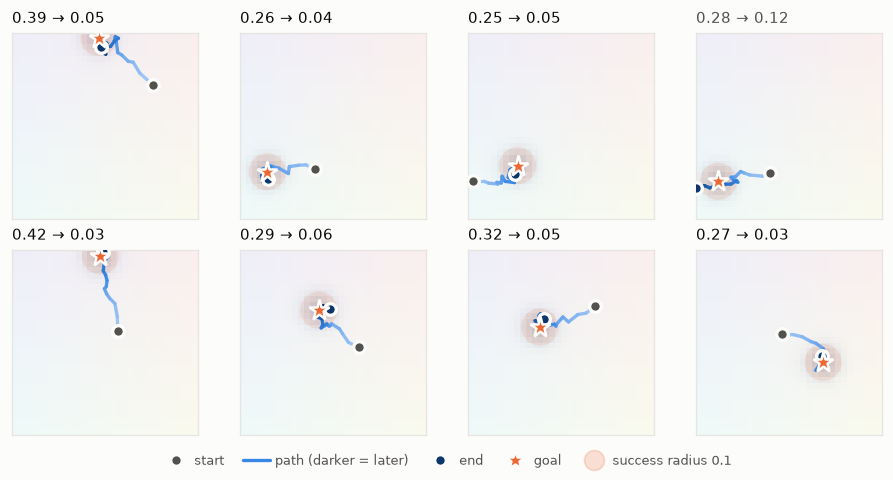

In [5]:
plots.trajectories(paths[:8], goals[:8], background=env.render(goals[:8]))